In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import h5py
import scipy.sparse as sp
import yaml
import time
import gget
from itertools import combinations
import anndata as an
import scanpy as sc
# import rapids_singlecell as rsc
from scipy.stats import median_abs_deviation
import scanpy.external as sce

# import rmm
# import cupy as cp
# from rmm.allocators.cupy import rmm_cupy_allocator

# rmm.reinitialize(
#     managed_memory=True,
#     pool_allocator=False,
# )
# cp.cuda.set_allocator(rmm_cupy_allocator)

sc.settings.verbosity = 2

In [2]:
%%time
fpath = "/nfs/turbo/umms-indikar/shared/projects/HSC/pipeline_outputs/cc_fibroblast_full/scfib/scfib.gene_raw_feature_bc_matrix/"

fib_adata = sc.read_10x_mtx(fpath)
fib_adata.obs['batch'] = 'fib'

# fib_adata.obs_names = [f"{cb}_fib" for cb in fib_adata.obs_names]

print(f"Batch: Fibroblast")
print(f"\tTotal UMIs: {int(np.sum(fib_adata.X))}")
print(f"\tCells: {fib_adata.shape[0]}")
print(f"\tGenes: {fib_adata.shape[1]}")

fib_adata

Batch: Fibroblast
	Total UMIs: 106198200
	Cells: 8963
	Genes: 23635
CPU times: user 7.87 s, sys: 1.58 s, total: 9.46 s
Wall time: 10.1 s


AnnData object with n_obs × n_vars = 8963 × 23635
    obs: 'batch'
    var: 'gene_ids', 'feature_types'

In [4]:
fib_adata.obs.head()

,batch
AAACCAAAGGGTAGCA-1,fib
AAACCAAAGTAAGGGT-1,fib
AAACCATTCAGGTAGG-1,fib
AAACCATTCCAGCCCT-1,fib
AAACCATTCGTGACCG-1,fib


In [5]:
# feature barcode data
fpath = "/nfs/turbo/umms-indikar/shared/projects/HSC/pipeline_outputs/cc_fibroblast_full/sc_fib_tsb_rerun/feature_barcodes/fbc_map.csv"
df = pd.read_csv(fpath)

# Sum columns for each condition:
df['G1'] = df.loc[:, df.columns.str.endswith('G1')].sum(axis=1)
df['S'] = df.loc[:, df.columns.str.endswith('S')].sum(axis=1)
df['G2M'] = df.loc[:, df.columns.str.endswith('G2M')].sum(axis=1)

# create a new dataframe with only the cell barcode and the summed conditions:
df = df[['cell_barcode', 'G1', 'S', 'G2M']]

df = df.groupby('cell_barcode', as_index=False).sum()
df['phase'] = df[['G1', 'S', 'G2M']].idxmax(axis=1)
df['cell_barcode'] = df['cell_barcode'] + "-1"
print(f"{df.shape=}")
barcode_map = dict(zip(df['cell_barcode'].values, df['phase'].values))
display(df.head())

# add to adata
fib_adata.obs['barcoded_phase'] = fib_adata.obs.index.map(barcode_map)
print(fib_adata.obs['barcoded_phase'].value_counts(dropna=False).to_string())

df.shape=(10715, 5)


,cell_barcode,G1,S,G2M,phase
0,AAACCAAAGGGTAGCA-1,0.0,1.0,8.0,G2M
1,AAACCAAAGTAAGGGT-1,2.0,0.0,0.0,G1
2,AAACCATTCAGGTAGG-1,2.0,0.0,0.0,G1
3,AAACCATTCCAGCCCT-1,3.0,9.0,0.0,S
4,AAACCATTCGTGACCG-1,5.0,1.0,0.0,G1


barcoded_phase
G1     5733
S      1689
G2M    1453
NaN      88


In [6]:
%%time 
# === Load and filter GTF ===
gpath = "/nfs/turbo/umms-indikar/shared/projects/HSC/data/RefGenome/refdata-gex-GRCh38-2024-A_genes.csv.gz"

gtf = pd.read_csv(gpath)

gtf = gtf[gtf['Feature'] == 'gene']

print(gtf.shape)
gtf.head()

(38606, 27)
CPU times: user 13 s, sys: 1.97 s, total: 14.9 s
Wall time: 15.3 s


,Chromosome,Source,Feature,Start,End,Score,Strand,Frame,gene_id,gene_version,...,transcript_name,transcript_support_level,havana_transcript,exon_number,exon_id,exon_version,hgnc_id,havana_gene,protein_id,ccdsid
0,GL000009.2,ENSEMBL,gene,56139,58376,.,-,.,ENSG00000278704,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,GL000194.1,ENSEMBL,gene,53589,115018,.,-,.,ENSG00000277400,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20,GL000194.1,ENSEMBL,gene,53593,115055,.,-,.,ENSG00000274847,1,...,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:31102,NaN,NaN,NaN
34,GL000195.1,ENSEMBL,gene,42938,49164,.,-,.,ENSG00000276256,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
44,GL000213.1,ENSEMBL,gene,108006,139659,.,-,.,ENSG00000277630,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Extract only genes that are present in adata
gdf = gtf[gtf['gene_name'].isin(fib_adata.var_names)]
print(f"Matched with AnnData var names: {gdf['gene_name'].nunique()} entries")
print(f"N duplicate names: {len(gdf) - gdf['gene_name'].nunique()}")

# Select columns to include in gene annotation
keep_columns = ['gene_id', 'gene_name', 'gene_type', 'Chromosome']

# drop duplicate gene names
gdf = gdf[keep_columns].drop_duplicates(subset='gene_name').dropna(subset=['gene_name']).reset_index(drop=True)

print(f"\nFinal gene annotation shape: {gdf.shape}")

# Merge with adata.var
print("\nMerging transcript annotations (gdf) into adata.var...")
fib_adata.var = pd.concat([
    fib_adata.var,
    gdf.set_index('gene_name')
], axis=1)

print("Gene annotations successfully merged into adata.var.")
fib_adata

Matched with AnnData var names: 23635 entries
N duplicate names: 19

Final gene annotation shape: (23635, 4)

Merging transcript annotations (gdf) into adata.var...
Gene annotations successfully merged into adata.var.


AnnData object with n_obs × n_vars = 8963 × 23635
    obs: 'batch', 'barcoded_phase'
    var: 'gene_ids', 'feature_types', 'gene_id', 'gene_type', 'Chromosome'

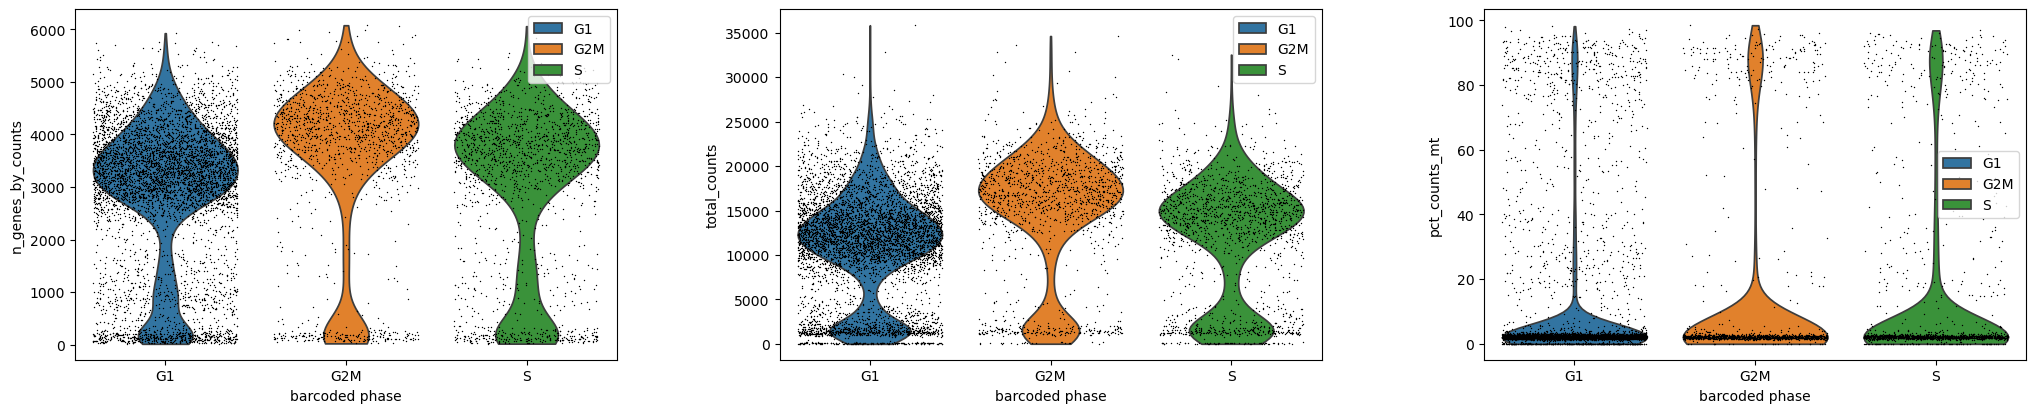

In [8]:
adata = fib_adata.copy()

adata.raw = adata  # keep full dimension safe

adata.layers['raw_counts'] = adata.X.copy()

# mitochondrial genes, "MT-" for human, "Mt-" for mouse
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], 
    inplace=True, log1p=True
)

plt.rcdefaults()
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
    groupby='barcoded_phase',
)

In [9]:
### remove outlier cells
def is_outlier(adata, metric: str, nmads: int):
    M = adata.obs[metric]

    if len(M) < 2 or M.isnull().all():
        return pd.Series(False, index=adata.obs.index)

    median_val = np.median(M)
    mad_val = median_abs_deviation(M)
    print(f'{metric}:\tMedian val: {median_val}, MAD val: {mad_val}')

    if mad_val == 0:
        return pd.Series(False, index=adata.obs.index)

    outliers = (M < median_val - nmads * mad_val) | \
               (M > median_val + nmads * mad_val)

    return outliers



### determine outliers
adata.obs["outlier"] = (
    is_outlier(adata, "log1p_total_counts", 5)
    | is_outlier(adata, "log1p_n_genes_by_counts", 5)
)

print("Number of outlier cells based on counts:")
print(adata.obs['outlier'].sum())


adata.obs["mt_outlier"] = (
    is_outlier(adata, "pct_counts_mt", 3)
    | (adata.obs["pct_counts_mt"] > 20)
)

print("\nNumber of outlier cells based on pct mito:")
print(adata.obs['mt_outlier'].sum())


init_cells = adata.n_obs
print(f"Total number of cells: {init_cells}")

print("\nFiltering...")
adata = adata[(~adata.obs.outlier) & (~adata.obs.mt_outlier)].copy()

final_cells = adata.n_obs

print(f"\nRemoved {init_cells - final_cells} total cells.")
print(f"\nTotal cells after filtering of low quality cells: {final_cells}")

log1p_total_counts:	Median val: 9.460709571838379, MAD val: 0.262542724609375
log1p_n_genes_by_counts:	Median val: 8.133293861222633, MAD val: 0.18885720899026914
Number of outlier cells based on counts:
1676
pct_counts_mt:	Median val: 2.1964519023895264, MAD val: 0.39515507221221924

Number of outlier cells based on pct mito:
2042
Total number of cells: 8963

Filtering...

Removed 2137 total cells.

Total cells after filtering of low quality cells: 6826


In [10]:
print("Filtering genes...\n")

sc.pp.filter_genes(adata, min_counts=10)

print("\nNormalizing counts to 10,000...\n")
sc.pp.normalize_total(
    adata,
    target_sum=1e4,
)

# log transform normalized counts
sc.pp.log1p(adata)

# save log normalized counts
adata.layers['log_norm'] = adata.X.copy()

adata

Filtering genes...

filtered out 3696 genes that are detected in less than 10 counts

Normalizing counts to 10,000...

normalizing counts per cell
    finished (0:00:00)


AnnData object with n_obs × n_vars = 6826 × 19939
    obs: 'batch', 'barcoded_phase', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'mt_outlier'
    var: 'gene_ids', 'feature_types', 'gene_id', 'gene_type', 'Chromosome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts'
    uns: 'barcoded_phase_colors', 'log1p'
    layers: 'raw_counts', 'log_norm'

In [11]:
%%time
regev_genes = [x.strip() for x in open('./resources/regev_lab_cell_cycle_genes.txt')]

s_genes = regev_genes[:43]
g2m_genes = regev_genes[43:]

adata.X = adata.layers['log_norm'].copy()

sc.tl.score_genes_cell_cycle(
    adata,
    s_genes=s_genes,
    g2m_genes=g2m_genes,
)

adata.obs[['phase']].head()

calculating cell cycle phase
computing score 'S_score'
    finished (0:00:00)
computing score 'G2M_score'
    finished (0:00:00)
CPU times: user 525 ms, sys: 528 ms, total: 1.05 s
Wall time: 1.11 s


,phase
AAACCAAAGGGTAGCA-1,G2M
AAACCAAAGTAAGGGT-1,G1
AAACCATTCAGGTAGG-1,G2M
AAACCATTCCAGCCCT-1,G1
AAACCATTCGTGACCG-1,G1


extracting highly variable genes
Number of HVG: 2000


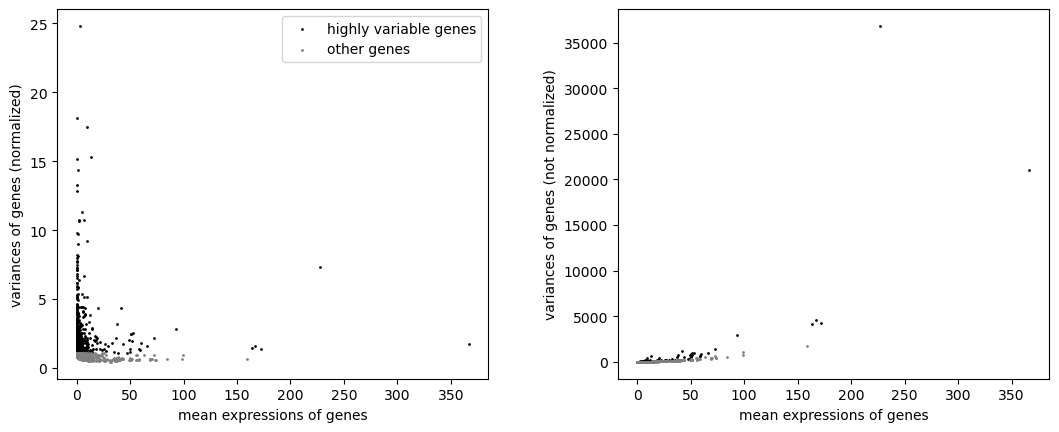

computing PCA
    with n_comps=50
    finished (0:00:02)


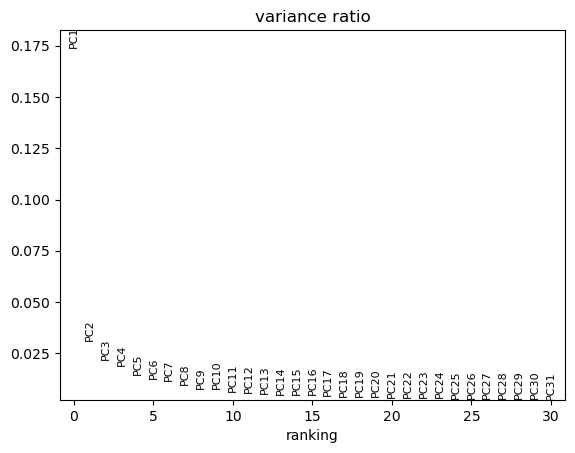

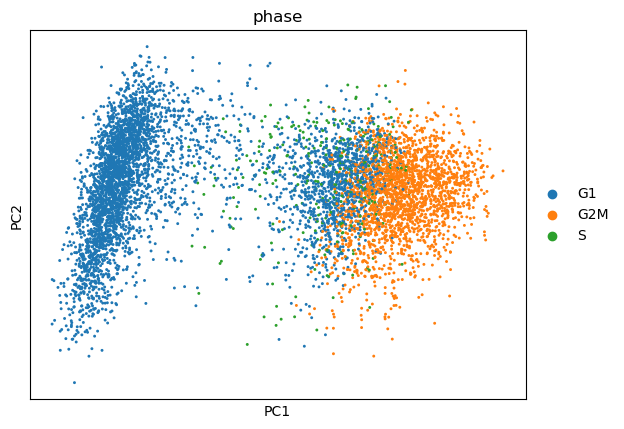

AnnData object with n_obs × n_vars = 6826 × 19939
    obs: 'batch', 'barcoded_phase', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'mt_outlier', 'S_score', 'G2M_score', 'phase'
    var: 'gene_ids', 'feature_types', 'gene_id', 'gene_type', 'Chromosome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'barcoded_phase_colors', 'log1p', 'hvg', 'pca', 'phase_colors'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'raw_counts', 'log_norm'

In [12]:
### HVGs
adata.X = adata.layers['raw_counts'].copy()

sc.pp.highly_variable_genes(
    adata,
    flavor='seurat_v3',
)

print(f"Number of HVG: {adata.var['highly_variable'].sum()}")

plt.rcdefaults()
sc.pl.highly_variable_genes(adata)

adata.X = adata.layers['log_norm'].copy()

### PCA
sc.pp.pca(adata)

sc.pl.pca_variance_ratio(adata)
sc.pl.pca(adata, color='phase')

adata